# A/B Testing Analysis: Landing Page Experiment

## Objective
An e-commerce company introduced a new landing page and conducted an A/B test to determine whether the redesign improves user conversion rates.

This project analyzes the experiment data using statistical testing and regression analysis to evaluate whether the new landing page leads to a statistically significant increase in conversions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

In [2]:
df=pd.read_csv("../data/ab_data.csv")
countries=pd.read_csv("../data/countries.csv")

In [9]:
df=df.drop_duplicates(subset='user_id')

In [10]:
df['user_id'].duplicated().sum()

0

# Finding Mismatched Rows

In [12]:
df_mismatch=df[
((df['group']=='control')&(df['landing_page']=='new_page'))|
((df['group']=='treatment')&(df['landing_page']=='old_page'))]

df_mismatch.shape

(2044, 5)

In [14]:
df=df.drop(df_mismatch.index)

In [16]:
df.groupby(['group','landing_page']).size()

group      landing_page
control    old_page        144226
treatment  new_page        144314
dtype: int64

In [26]:
df_mismatch = df[
    ((df['group'] == 'control') & (df['landing_page'] == 'new_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'old_page'))
]

df_mismatch.shape

(0, 5)

In [27]:
df['converted'].mean()

0.11950856033825466

In [28]:
df.groupby('group')['converted'].mean()

group
control      0.120290
treatment    0.118727
Name: converted, dtype: float64

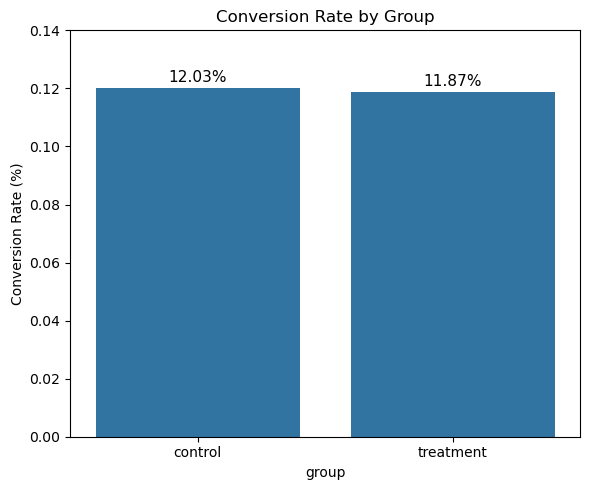

In [92]:
conversion_rates = df.groupby('group')['converted'].mean().reset_index()
plt.figure(figsize=(6,5))

ax=sns.barplot(x='group', y='converted', data=conversion_rates)

plt.title("Conversion Rate by Group")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0,0.14)

for i, row in conversion_rates.iterrows():
    ax.text(i, row['converted'] + 0.002, f"{row['converted']*100:.2f}%", 
            ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("../visuals/conversion_rate_by_group.png")

plt.show()

### Conversion Rate Analysis

The overall conversion rate of the dataset is approximately 11.95%.

When comparing the two experiment groups:
- Control group conversion rate: 12.03%
- Treatment group conversion rate: 11.87%

The control group (old landing page) shows a slightly higher conversion rate than the treatment group (new landing page). However, the difference is very small and requires statistical testing to determine whether it is statistically significant.

## Hypothesis Testing

Null Hypothesis (H0):
The new landing page does not improve the conversion rate.

H0: Conversion_new ≤ Conversion_old

Alternative Hypothesis (H1):
The new landing page improves the conversion rate.

H1: Conversion_new > Conversion_old

In [29]:
convert_old = df[df['group']=='control']['converted'].sum()
convert_new = df[df['group']=='treatment']['converted'].sum()

convert_old, convert_new

(17349, 17134)

In [30]:
n_old=df[df['group']=='control'].shape[0]
n_new=df[df['group']=='treatment'].shape[0]

n_old,n_new

(144226, 144314)

In [31]:
from statsmodels.stats.proportion import proportions_ztest

z_stat, p_value = proportions_ztest(
    [convert_new, convert_old],
    [n_new, n_old]
)

z_stat, p_value

(-1.2942367891190543, 0.19558364287881436)

### Hypothesis Test Results

A two-proportion Z-test was conducted to compare the conversion rates between the control group (old landing page) and the treatment group (new landing page).

Results:
- Control conversion rate: 12.03%
- Treatment conversion rate: 11.87%
- Z-statistic: -1.29
- P-value: 0.1956

Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis.

This indicates that the new landing page does not significantly improve the conversion rate compared to the old landing page.

### Business Recommendation

Based on the results of the A/B test, the new landing page does not provide a statistically significant improvement in conversion rates. Therefore, there is no strong evidence to replace the old landing page with the new version.

### Country Segmentation

In [32]:
df=df.merge(countries, on='user_id')

In [33]:
df.head()

,user_id,timestamp,group,landing_page,converted,country
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,US
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,US
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,US
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,US
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,US


In [34]:
df['country'].value_counts()

country
US    202185
UK     71961
CA     14394
Name: count, dtype: int64

In [35]:
df.groupby('country')['converted'].mean()

country
CA    0.115256
UK    0.120496
US    0.119460
Name: converted, dtype: float64

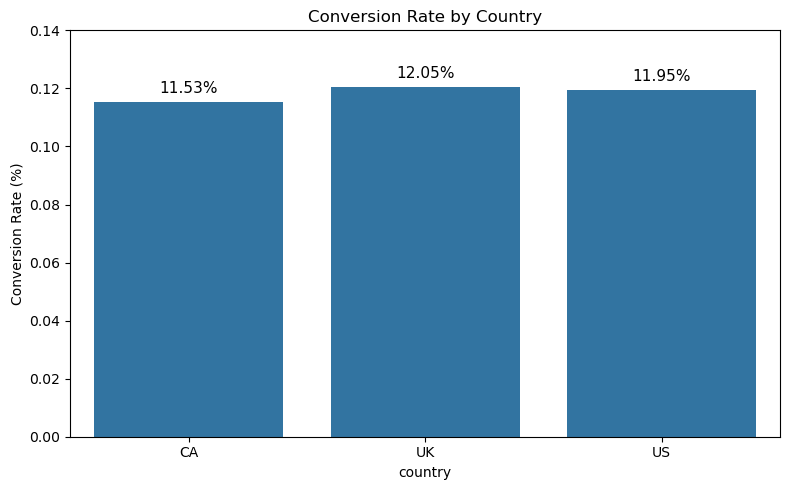

In [93]:
country_rates = df.groupby('country')['converted'].mean().reset_index()
plt.figure(figsize=(8,5))

ax=sns.barplot(x='country', y='converted', data=country_rates, errorbar=None)

plt.title("Conversion Rate by Country")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, 0.14)

for i, row in country_rates.iterrows():
    ax.text(i, row['converted'] + 0.003, f"{row['converted']*100:.2f}%", 
            ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("../visuals/conversion_rate_by_country.png")

plt.show()

In [36]:
df.groupby(['country','group'])['converted'].mean()

country  group    
CA       control      0.118801
         treatment    0.111770
UK       control      0.119945
         treatment    0.121051
US       control      0.120519
         treatment    0.118403
Name: converted, dtype: float64

In [38]:
df.groupby(['country','landing_page'])['converted'].mean()

country  landing_page
CA       new_page        0.111770
         old_page        0.118801
UK       new_page        0.121051
         old_page        0.119945
US       new_page        0.118403
         old_page        0.120519
Name: converted, dtype: float64

### Country Segmentation Analysis

The dataset was merged with user country information to examine whether the experiment behaved differently across regions.

User distribution shows that most users are from the United States, followed by the United Kingdom and Canada.

Conversion rate analysis by country shows:
- UK: 12.05%
- US: 11.95%
- CA: 11.53%

Further analysis comparing control and treatment groups within each country indicates that the new landing page performs slightly better in the UK, but the old page performs better in the US and Canada.

However, these differences are very small and do not indicate a strong or consistent advantage for the new page across countries.

## Logistic Regression Analysis

Logistic regression is used to examine whether the landing page has a statistically significant effect on conversion when controlling for user country.

In [39]:
import statsmodels.api as sm

In [40]:
df['ab_page'] = df['landing_page'].apply(lambda x: 1 if x == 'new_page' else 0)

In [47]:
country_dummies = pd.get_dummies(df['country'], drop_first=True)

In [48]:
country_dummies.head()

,UK,US
0,False,True
1,False,True
2,False,True
3,False,True
4,False,True


In [49]:
df=df.join(country_dummies)

In [50]:
df.columns

Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted', 'country',
       'ab_page', 'UK', 'US'],
      dtype='object')

In [51]:
df[['UK','US']] = df[['UK','US']].astype(int)

In [52]:
df[['UK','US']].head()

,UK,US
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [53]:
df[['ab_page','UK','US']].dtypes

ab_page    int64
UK         int32
US         int32
dtype: object

In [54]:
logit_model = sm.Logit(df['converted'], sm.add_constant(df[['ab_page','UK','US']]))
result = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.365936
         Iterations 6


In [55]:
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               288540
Model:                          Logit   Df Residuals:                   288536
Method:                           MLE   Df Model:                            3
Date:                Mon, 16 Mar 2026   Pseudo R-squ.:               2.288e-05
Time:                        11:58:19   Log-Likelihood:            -1.0559e+05
converged:                       True   LL-Null:                   -1.0559e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1845
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0307      0.027    -75.975      0.000      -2.083      -1.978
ab_page       -0.0148      0.011     -1.290      0.197      -0.037       0.008
UK             0.0503      0.029      1.765      0.078      -0.006       0.106
US             0.0405      0.027      1.502      0.133      -0.012       0.093
==============================================================================
"""

### Logistic Regression Analysis

A logistic regression model was used to evaluate whether the landing page influences conversion probability while controlling for user country.

Results:

- The coefficient for the new landing page (ab_page) is -0.0148.
- The p-value for ab_page is 0.197, which is greater than the significance level of 0.05.

This indicates that the new landing page does not have a statistically significant effect on conversion rates.

Country variables (UK and US) also show p-values greater than 0.05, suggesting that user location does not significantly impact conversion probability.

Overall, the logistic regression results support the earlier A/B test findings that the new landing page does not significantly improve conversion rates.

### Final Business Insight:
The new landing page does not provide a statistically significant improvement in conversion rates. Therefore, there is no strong evidence to replace the existing landing page